<a href="https://colab.research.google.com/github/Ludwig-Ivan/Panda/blob/main/comida.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Preparar el entorno

In [8]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo " NO HAY GPU: Entorno de ejecución → Cambiar tipo → T4 GPU"
!pip install -q -U transformers huggingface_hub

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Conectar Google Drive
Ahí se guardan el modelo y la caché, para no perderlos si Colab se desconecta. Acepta el permiso que aparece.

In [9]:
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/n5k_runs'
import os; os.makedirs(OUT, exist_ok=True)
print('Resultados en', OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados en /content/drive/MyDrive/n5k_runs


## 3. Configuración
Lo único que normalmente cambiarías. **Opción A** (recomendada): parte de los pesos de CalorieK y los sigue
entrenando. **Opción B**: entrena desde SigLIP2 base.

In [10]:
OPCION = "A"            # "A" = partir de CalorieK (recomendado) | "B" = desde SigLIP2 base

EPOCHS      = 15   if OPCION == "A" else 30
LR_HEAD     = 2e-4 if OPCION == "A" else 1e-3   # learning rate de la cabeza
LR_BACKBONE = 1e-5 if OPCION == "A" else 2e-5   # learning rate de SigLIP2 (bajo, para no "olvidar")
BATCH_SIZE  = 32        # bájalo a 16 si sale "CUDA out of memory"
IMG_SIZE    = 224
WARMUP_EPOCHS = 1
VAL_FRAC    = 0.1       # 10% del train oficial se usa para validación
MAX_CALORIES = None     # p. ej. 2000 para descartar platillos raros del entrenamiento
USAR_CACHE  = True      # guarda en Drive las fotos ya reducidas (~0.5 GB) para la próxima sesión
NUM_WORKERS = 2
SEED        = 0

BASE_URL = "https://storage.googleapis.com/nutrition5k_dataset/nutrition5k_dataset"
OUT = globals().get("OUT", "/content/runs")      # si no conectaste Drive, se guarda en /content/runs
RUN_DIR = f"{OUT}/caloriek_ft" if OPCION == "A" else f"{OUT}/siglip2"
CACHE_FILE = f"{OUT}/n5k_cache_{IMG_SIZE}.pt" if USAR_CACHE else None

import os, csv, io, json, math, random, time
import numpy as np, torch
from PIL import Image
from torchvision.transforms.v2 import functional as TF
NUTRIENTS = ["calorias", "masa", "grasa", "carbohidrato", "proteina"]
UNITS = {"calorias": "kcal", "masa": "g", "grasa": "g", "carbohidrato": "g", "proteina": "g"}
os.makedirs(RUN_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Opción", OPCION, "| dispositivo:", DEVICE, "| resultados en", RUN_DIR)

Opción A | dispositivo: cuda | resultados en /content/drive/MyDrive/n5k_runs/caloriek_ft


## 4. Leer los datos desde la web
Lee los metadatos y las listas oficiales de train/test, y baja las ~3,500 fotos cenitales **a memoria**
(reducidas a 224×224, unos 0.5 GB de RAM). No se guarda ninguna imagen en disco. Si `USAR_CACHE` está activo,
la siguiente vez se cargan desde Drive en segundos.

In [11]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

session = requests.Session()
_adapter = HTTPAdapter(pool_connections=64, pool_maxsize=64,
                       max_retries=Retry(total=5, backoff_factor=0.5, status_forcelist=[429, 500, 502, 503, 504]))
session.mount("http://", _adapter); session.mount("https://", _adapter)

def get_bytes(rel):
    """Lee un archivo del dataset por URL. Devuelve None si no existe (404)."""
    r = session.get(f"{BASE_URL}/{rel}", timeout=60)
    if r.status_code == 404:
        return None
    r.raise_for_status()
    return r.content

def parse_metadata(text, meta):
    """Cada fila: dish_id, calorías, masa, grasa, carbs, proteína, y luego 7 campos por ingrediente."""
    for row in csv.reader(io.StringIO(text)):
        if len(row) < 6:
            continue
        try:
            meta[row[0].strip()] = [float(x) for x in row[1:6]]
        except ValueError:
            pass

def label_ok(d):
    t = meta.get(d)
    return t is not None and t[1] > 0 and (MAX_CALORIES is None or t[0] <= MAX_CALORIES)

# 4.1 Metadatos (nutrientes de cada platillo)
meta = {}
for f in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
    data = get_bytes(f"metadata/{f}")
    if data is not None:
        parse_metadata(data.decode("utf-8"), meta)
assert meta, f"No pude leer los metadatos desde {BASE_URL}. ¿Hay internet?"
print(f"Metadatos: {len(meta)} platillos")

# 4.2 Splits oficiales
read_ids = lambda name: [l.strip() for l in get_bytes(f"dish_ids/splits/rgb_{name}_ids.txt").decode().splitlines() if l.strip()]
train_all = [d for d in read_ids("train") if label_ok(d)]
test_ids = [d for d in read_ids("test") if label_ok(d)]
random.Random(SEED).shuffle(train_all)
n_val = max(1, int(len(train_all) * VAL_FRAC))
val_ids, train_ids = train_all[:n_val], train_all[n_val:]

# 4.3 Fotos a memoria (en paralelo)
def fetch_photo(d):
    data = get_bytes(f"imagery/realsense_overhead/{d}/rgb.png")
    if data is None:
        return None
    x = torch.from_numpy(np.array(Image.open(io.BytesIO(data)).convert("RGB"))).permute(2, 0, 1).float()
    x = TF.resize(x, [IMG_SIZE, IMG_SIZE], antialias=True)
    return x.round().clamp(0, 255).to(torch.uint8)

store = {}
if CACHE_FILE and Path(CACHE_FILE).exists():
    c = torch.load(CACHE_FILE, map_location="cpu", weights_only=True)
    if c["img_size"] == IMG_SIZE:
        store = c["images"]
        print(f"Caché: {len(store)} fotos cargadas desde {CACHE_FILE}")

all_ids = list(dict.fromkeys(train_ids + val_ids + test_ids))
todo = [d for d in all_ids if d not in store]
missing, errors, t0 = [], [], time.time()
if todo:
    print(f"Bajando {len(todo)} fotos (32 conexiones en paralelo)...")
    with ThreadPoolExecutor(32) as ex:
        futs = {ex.submit(fetch_photo, d): d for d in todo}
        for i, f in enumerate(as_completed(futs), 1):
            d = futs[f]
            try:
                t = f.result()
                if t is None: missing.append(d)
                else: store[d] = t
            except Exception as e:
                errors.append((d, repr(e)))
            if i % 250 == 0 or i == len(todo):
                print(f"  {i}/{len(todo)}  ({time.time() - t0:.0f}s)", flush=True)
    if CACHE_FILE and len(todo) > len(missing) + len(errors):   # solo si hubo fotos nuevas
        torch.save({"img_size": IMG_SIZE, "images": store}, CACHE_FILE)
        print("Caché guardada en", CACHE_FILE)

if missing: print(f"{len(missing)} platillos no tienen foto en el bucket: se omiten")
if errors:  print(f"{len(errors)} fotos fallaron por red: se omiten (ej.: {errors[0][1][:100]})")
train_ids, val_ids, test_ids = ([d for d in ids if d in store] for ids in (train_ids, val_ids, test_ids))
print(f"Listo -> train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)} | "
      f"{sum(t.numel() for t in store.values()) / 1e6:.0f} MB en memoria")

Metadatos: 5006 platillos
Caché: 3262 fotos cargadas desde /content/drive/MyDrive/n5k_runs/n5k_cache_224.pt
Bajando 1506 fotos (32 conexiones en paralelo)...
  250/1506  (2s)
  500/1506  (4s)
  750/1506  (6s)
  1000/1506  (8s)
  1250/1506  (10s)
  1500/1506  (12s)
  1506/1506  (12s)
1506 platillos no tienen foto en el bucket: se omiten
Listo -> train 2494 | val 261 | test 507 | 491 MB en memoria


## 5. Dataset y aumento de datos
Convierte cada platillo en (imagen, 5 nutrientes). Durante el entrenamiento gira, voltea y cambia un poco
la luz de las fotos para que el modelo no memorice. No recorta, porque eso cambiaría la cantidad de comida.

In [12]:
from torch.utils.data import Dataset, DataLoader

class N5kDataset(Dataset):
    def __init__(self, ids, train=False):
        self.ids, self.train = list(ids), train

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        d = self.ids[i]
        x = store[d].float() / 255.0
        if self.train:
            if random.random() < 0.5: x = TF.horizontal_flip(x)
            if random.random() < 0.5: x = TF.vertical_flip(x)
            x = TF.rotate(x, random.uniform(-180, 180), interpolation=TF.InterpolationMode.BILINEAR)
            x = TF.adjust_brightness(x, random.uniform(0.8, 1.2))
            x = TF.adjust_contrast(x, random.uniform(0.8, 1.2))
            x = TF.adjust_saturation(x, random.uniform(0.8, 1.2))
            x = TF.adjust_hue(x, random.uniform(-0.03, 0.03)).clamp(0, 1)
        x = (x - 0.5) / 0.5                      # normalización que espera SigLIP2
        return x, torch.tensor(meta[d], dtype=torch.float32), d

kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_dl = DataLoader(N5kDataset(train_ids, train=True), shuffle=True, drop_last=len(train_ids) > BATCH_SIZE, **kw)
val_dl   = DataLoader(N5kDataset(val_ids), **kw)
test_dl  = DataLoader(N5kDataset(test_ids), **kw)
x, y, _ = next(iter(val_dl))
print("Batch de ejemplo:", tuple(x.shape), "| etiquetas:", tuple(y.shape))

Batch de ejemplo: (32, 3, 224, 224) | etiquetas: (32, 5)


## 6. El modelo
SigLIP2 resume la foto en 768 números y la cabeza los convierte en los 5 nutrientes. La salida usa *softplus*,
así que nunca da valores negativos. En la opción A se cargan los pesos de CalorieK y se reordenan sus salidas,
porque CalorieK entrega `[kcal, masa, proteína, carbs, grasa]` y aquí usamos `[kcal, masa, grasa, carbs, proteína]`.

In [13]:
import torch.nn as nn, torch.nn.functional as F
from transformers import SiglipVisionConfig, SiglipVisionModel

SIGLIP_ID = "google/siglip2-base-patch16-224"
CALORIEK_TO_OURS = [0, 1, 4, 3, 2]

class NutritionHead(nn.Module):
    """Igual a la cabeza de CalorieK, para poder cargar sus pesos."""
    def __init__(self, d=768):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 768), nn.GELU(), nn.Dropout(.15),
                                 nn.Linear(768, 256), nn.GELU(), nn.Dropout(.10), nn.Linear(256, 5))
    def forward(self, x):
        return F.softplus(self.net(x))

class NutritionModel(nn.Module):
    def __init__(self, vision_config=None):
        super().__init__()
        self.backbone = (SiglipVisionModel(SiglipVisionConfig(**vision_config)) if vision_config
                         else SiglipVisionModel.from_pretrained(SIGLIP_ID))
        self.head = NutritionHead(self.backbone.config.hidden_size)
        self.register_buffer("scale", torch.ones(5))   # promedio de cada nutriente (o 1 con CalorieK)

    def forward(self, x):
        out = self.backbone(pixel_values=x)
        f = out.pooler_output if out.pooler_output is not None else out.last_hidden_state[:, 0]
        return self.head(f.float()) * self.scale       # valores en kcal y gramos

def load_caloriek(model):
    from huggingface_hub import hf_hub_download
    path = hf_hub_download("Dralkh/CalorieK", "caloriek.pt")
    try:
        state = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        print("Aviso: el archivo de CalorieK necesita weights_only=False (ejecuta código del archivo). "
              "Si no confías en el autor, usa OPCION = 'B'.")
        state = torch.load(path, map_location="cpu", weights_only=False)
    model.backbone.load_state_dict(state["vision_state"])
    model.head.load_state_dict(state["head_state"])
    last = model.head.net[-1]
    with torch.no_grad():
        last.weight.copy_(last.weight[CALORIEK_TO_OURS].clone())
        last.bias.copy_(last.bias[CALORIEK_TO_OURS].clone())
        model.scale.fill_(1.0)                          # CalorieK ya predice en unidades reales

print("Clases del modelo definidas")

Clases del modelo definidas


## 7. Crear el modelo
Descarga SigLIP2 (y CalorieK en la opción A) desde Hugging Face.

In [14]:
train_mean = torch.tensor([meta[d] for d in train_ids]).mean(0).clamp(min=1e-3)
model = NutritionModel()
if OPCION == "A":
    load_caloriek(model)
else:
    model.scale.copy_(train_mean)
model.to(DEVICE)
print(f"Modelo listo: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parámetros")

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip2-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.embeddings.token_embedding.weight                 | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.se

caloriek.pt: reconstructing file:   0%|          |  0.00B /  375MB            

caloriek.pt: downloading bytes:           |  0.00B            

Modelo listo: 93.7 M parámetros


## 8. Entrenar
Cada época imprime el error en validación. La `*` marca la mejor época hasta ahora, que se guarda en
`best.pt` en tu Drive. Al final se evalúa en el **test oficial** (fotos que el modelo nunca vio).

In [15]:
@torch.no_grad()
def evaluate(dl):
    model.eval()
    P, Y, ids = [], [], []
    for x, y, d in dl:
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            P.append(model(x.to(DEVICE)).float().cpu())
        Y.append(y); ids += list(d)
    P, Y = torch.cat(P), torch.cat(Y)
    mae = (P - Y).abs().mean(0); pct = 100 * mae / Y.mean(0)
    m = {n: {"mae": mae[i].item(), "pct_mae": pct[i].item()} for i, n in enumerate(NUTRIENTS)}
    m["mean_pct_mae"] = pct.mean().item()
    return m, P, Y, ids

fmt = lambda m: "  ".join(f"{n}: {m[n]['mae']:.1f}{UNITS[n]} ({m[n]['pct_mae']:.1f}%)" for n in NUTRIENTS)

if OPCION == "A":
    m0, *_ = evaluate(val_dl)
    print("CalorieK antes de entrenar (val):", f"%MAE medio {m0['mean_pct_mae']:.1f}% |", fmt(m0))

head_params = list(model.head.parameters())
head_ids = {id(p) for p in head_params}
opt = torch.optim.AdamW([{"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": LR_BACKBONE},
                         {"params": head_params, "lr": LR_HEAD}], weight_decay=1e-4)
steps, warm = EPOCHS * len(train_dl), WARMUP_EPOCHS * len(train_dl)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / max(1, warm) if s < warm
                                          else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
loss_fn = nn.SmoothL1Loss(beta=0.1)
loss_scale = train_mean.to(DEVICE)          # cada nutriente se divide por su promedio: pesan parecido
config = {"img_size": IMG_SIZE, "opcion": OPCION, "vision_config": model.backbone.config.to_dict()}

best = float("inf")
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); tot = n = 0
    for x, y, _ in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            pred = model(x)
        loss = loss_fn(pred.float() / loss_scale, y / loss_scale)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(x); n += len(x)
    val, *_ = evaluate(val_dl)
    star = ""
    if val["mean_pct_mae"] < best:
        best, star = val["mean_pct_mae"], " *"
        torch.save({"model": model.state_dict(), "config": config}, f"{RUN_DIR}/best.pt")
    print(f"[{epoch:03d}/{EPOCHS}] loss {tot / n:.4f} | val %MAE medio {val['mean_pct_mae']:.1f}% | "
          f"{time.time() - t0:.0f}s{star}\n      {fmt(val)}", flush=True)

model.load_state_dict(torch.load(f"{RUN_DIR}/best.pt", map_location=DEVICE, weights_only=False)["model"])
test_m, P, Y, ids = evaluate(test_dl)
json.dump(test_m, open(f"{RUN_DIR}/test_metrics.json", "w"), indent=2)
with open(f"{RUN_DIR}/test_predictions.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["dish_id"] + [f"{k}_real" for k in NUTRIENTS] + [f"{k}_pred" for k in NUTRIENTS])
    for i, d in enumerate(ids):
        w.writerow([d] + [f"{v:.2f}" for v in Y[i].tolist()] + [f"{v:.2f}" for v in P[i].tolist()])
print("\n=== TEST ===\n" + fmt(test_m) + f"\n%MAE medio: {test_m['mean_pct_mae']:.1f}%")
print("Guardado en", RUN_DIR)

CalorieK antes de entrenar (val): %MAE medio 40.4% | calorias: 86.8kcal (37.6%)  masa: 82.7g (41.3%)  grasa: 5.0g (42.3%)  carbohidrato: 6.3g (36.9%)  proteina: 7.1g (43.9%)
[001/15] loss 0.3054 | val %MAE medio 30.8% | 48s *
      calorias: 52.7kcal (22.8%)  masa: 54.7g (27.3%)  grasa: 4.5g (38.0%)  carbohidrato: 5.8g (33.8%)  proteina: 5.2g (32.2%)
[002/15] loss 0.2838 | val %MAE medio 27.8% | 36s *
      calorias: 51.0kcal (22.0%)  masa: 58.2g (29.1%)  grasa: 4.0g (33.5%)  carbohidrato: 4.4g (26.0%)  proteina: 4.6g (28.3%)
[003/15] loss 0.2617 | val %MAE medio 26.0% | 36s *
      calorias: 50.6kcal (21.9%)  masa: 49.6g (24.8%)  grasa: 3.9g (32.5%)  carbohidrato: 4.2g (24.5%)  proteina: 4.2g (26.2%)
[004/15] loss 0.2390 | val %MAE medio 24.2% | 35s *
      calorias: 48.3kcal (20.9%)  masa: 44.5g (22.2%)  grasa: 3.4g (28.2%)  carbohidrato: 4.3g (25.5%)  proteina: 3.9g (24.2%)
[005/15] loss 0.2183 | val %MAE medio 27.2% | 33s
      calorias: 53.8kcal (23.3%)  masa: 46.6g (23.3%)  grasa

## 9. Resultados en el test oficial
**MAE** = cuánto se equivoca en promedio. **%MAE** = ese error como porcentaje del promedio real.
En la gráfica, cada punto es un platillo: cuanto más cerca de la diagonal, mejor.

,MAE,%MAE
calorias,44.4,17.4
masa,32.1,16.2
grasa,3.3,25.9
carbohidrato,4.5,23.1
proteina,4.1,23.3


AttributeError: 'DataFrame' object has no attribute 'calories_real'

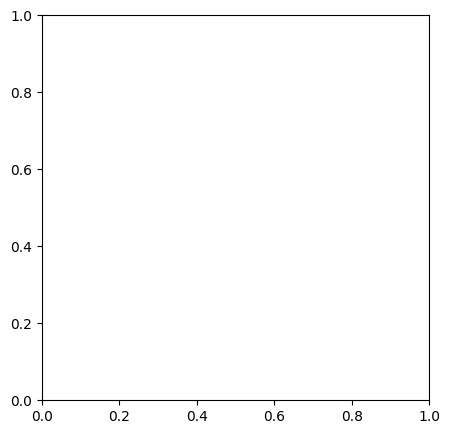

In [16]:
import pandas as pd, matplotlib.pyplot as plt
m = json.load(open(f"{RUN_DIR}/test_metrics.json"))
display(pd.DataFrame({k: v for k, v in m.items() if isinstance(v, dict)}).T.round(1)
        .rename(columns={"mae": "MAE", "pct_mae": "%MAE"}))
df = pd.read_csv(f"{RUN_DIR}/test_predictions.csv")
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df.calories_real, df.calories_pred, s=8, alpha=0.5)
lim = max(df.calories_real.max(), df.calories_pred.max())
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set_xlabel("Calorías reales (kcal)"); ax.set_ylabel("Calorías predichas (kcal)")
ax.set_title("Test: predicho vs. real"); plt.show()

## 10. Probar con tus fotos
Sube una o varias fotos **tomadas desde arriba**, con el plato completo y buena luz.

*¿Volviste otro día?* No hace falta reentrenar ni volver a leer los datos: corre las secciones **1, 2, 3 y 6**
(con la misma `OPCION` que entrenaste) y luego esta.

In [ ]:
from google.colab import files
ckpt = torch.load(f"{RUN_DIR}/best.pt", map_location="cpu", weights_only=False)
model = NutritionModel(ckpt["config"]["vision_config"])
model.load_state_dict(ckpt["model"]); model.to(DEVICE).eval()

def predecir(path):
    img = Image.open(path).convert("RGB")
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
    x = TF.resize(x, [ckpt["config"]["img_size"]] * 2, antialias=True)
    x = ((x - 0.5) / 0.5)[None].to(DEVICE)
    with torch.no_grad():
        y = model(x)[0].tolist()
    return dict(zip(NUTRIENTS, y))

for name in files.upload():
    r = predecir(name)
    print(f"\n{name}")
    for k, v in r.items():
        print(f"  {k:9s} {v:8.1f} {UNITS[k]}")